In [69]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")


In [70]:

train_df = pd.read_csv("/content/sample_data/dataset_B_training.csv")
test_df = pd.read_csv("/content/sample_data/dataset_B_testing.csv")

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

display(train_df.head())


Training dataset shape: (4756, 31)
Testing dataset shape: (4749, 30)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


In [71]:

# Display column names
print(train_df.columns.tolist())

# Display data types and non-null counts
train_df.info()

# Statistical summary
display(train_df.describe(include="all").T)


['respondent_id', 'h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'household_adults', 'household_children', 'employment_sector', 'number_chronic_med_conditions', 'h1n1_vaccine']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   h1n1_concern                   4741 non-null   float64
 2   h1n1_kno

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
h1n1_concern,4741.0,NaN,NaN,NaN,1.658933,0.892478,0.0,1.0,2.0,2.0,3.0
h1n1_knowledge,4734.0,NaN,NaN,NaN,1.30714,0.612811,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4739.0,NaN,NaN,NaN,0.057396,0.232622,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,NaN,NaN,NaN,0.74096,0.438154,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4752.0,NaN,NaN,NaN,0.077652,0.267651,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4748.0,NaN,NaN,NaN,0.842039,0.364743,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4747.0,NaN,NaN,NaN,0.359385,0.479871,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4741.0,NaN,NaN,NaN,0.341278,0.474189,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4736.0,NaN,NaN,NaN,0.704814,0.456174,0.0,0.0,1.0,1.0,1.0


In [72]:

missing_values = train_df.isnull().sum()

missing_percentage = (
    train_df.isnull().mean() * 100
).round(2)

missing_df = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
})

display(
    missing_df[missing_df["Missing Values"] > 0]
    .sort_values("Missing Values", ascending=False)
)


,Missing Values,Percentage
employment_sector,2364,49.71
health_insurance,1925,40.48
income_poverty,712,14.97
doctor_recc_h1n1,319,6.71
rent_or_own,315,6.62
employment_status,235,4.94
marital_status,226,4.75
education,224,4.71
child_under_6_months,134,2.82
health_worker,131,2.75


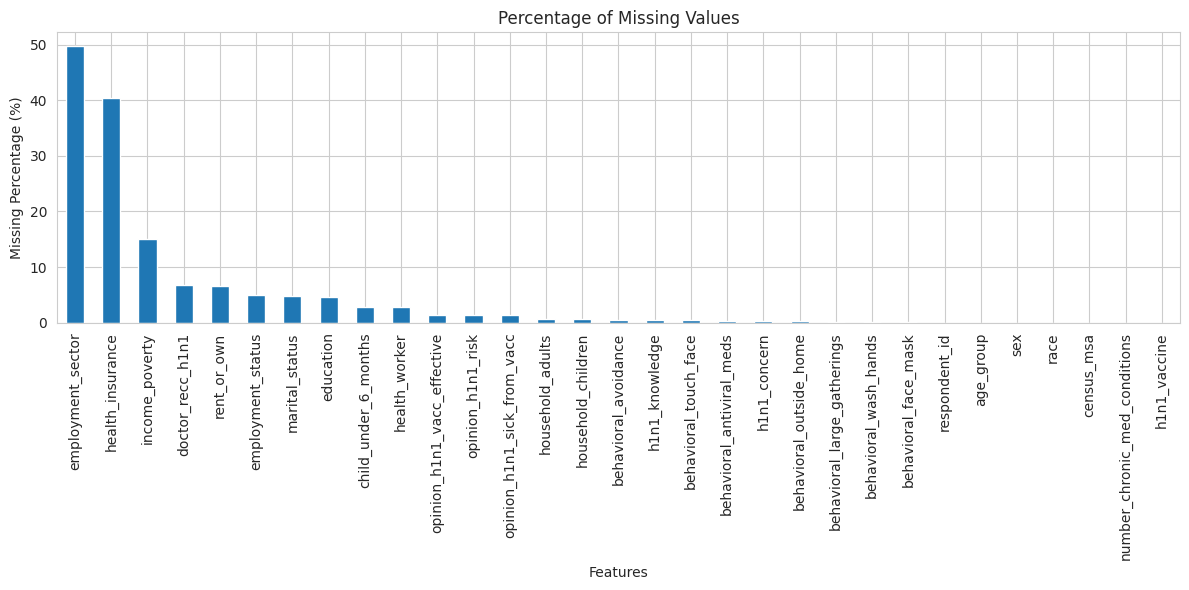

In [73]:

plt.figure(figsize=(12, 6))

missing_df["Percentage"].sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Percentage of Missing Values")
plt.ylabel("Missing Percentage (%)")
plt.xlabel("Features")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [74]:

print("Duplicate rows:", train_df.duplicated().sum())

print(
    "Duplicate respondent IDs:",
    train_df["respondent_id"].duplicated().sum()
)


Duplicate rows: 0
Duplicate respondent IDs: 0


h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64
h1n1_vaccine
0    60.59714
1    39.40286
Name: proportion, dtype: float64


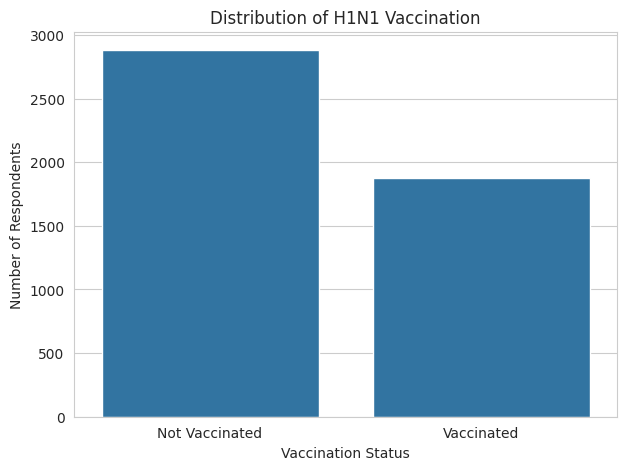

In [75]:

print(train_df["h1n1_vaccine"].value_counts())

print(
    train_df["h1n1_vaccine"]
    .value_counts(normalize=True) * 100
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x="h1n1_vaccine"
)

plt.title("Distribution of H1N1 Vaccination")
plt.xlabel("Vaccination Status")
plt.ylabel("Number of Respondents")
plt.xticks([0, 1], ["Not Vaccinated", "Vaccinated"])
plt.show()


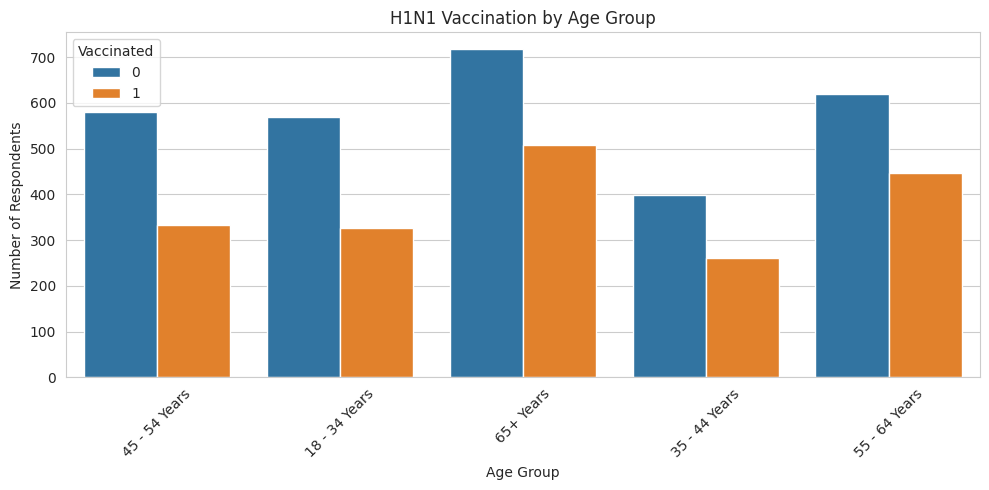

In [76]:

plt.figure(figsize=(10, 5))

sns.countplot(
    data=train_df,
    x="age_group",
    hue="h1n1_vaccine"
)

plt.title("H1N1 Vaccination by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=45)
plt.legend(title="Vaccinated")
plt.tight_layout()
plt.show()


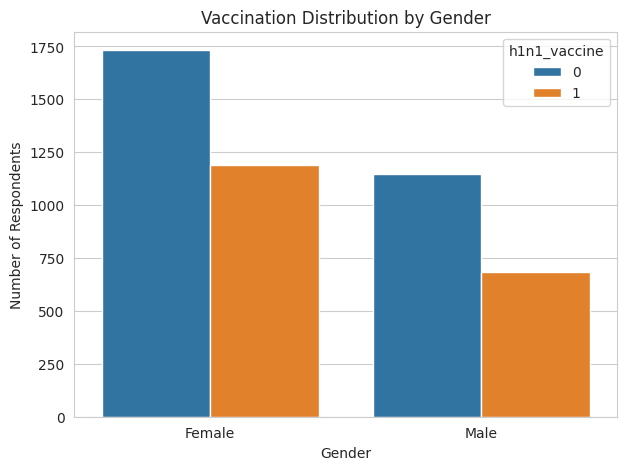

In [77]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x="sex",
    hue="h1n1_vaccine"
)

plt.title("Vaccination Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Respondents")
plt.show()


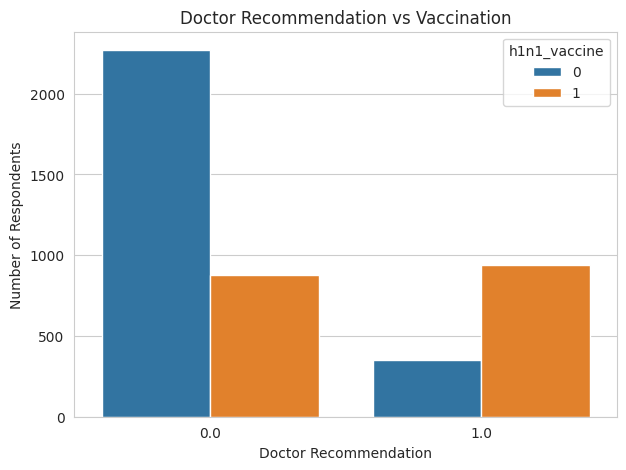

In [78]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x="doctor_recc_h1n1",
    hue="h1n1_vaccine"
)

plt.title("Doctor Recommendation vs Vaccination")
plt.xlabel("Doctor Recommendation")
plt.ylabel("Number of Respondents")
plt.show()


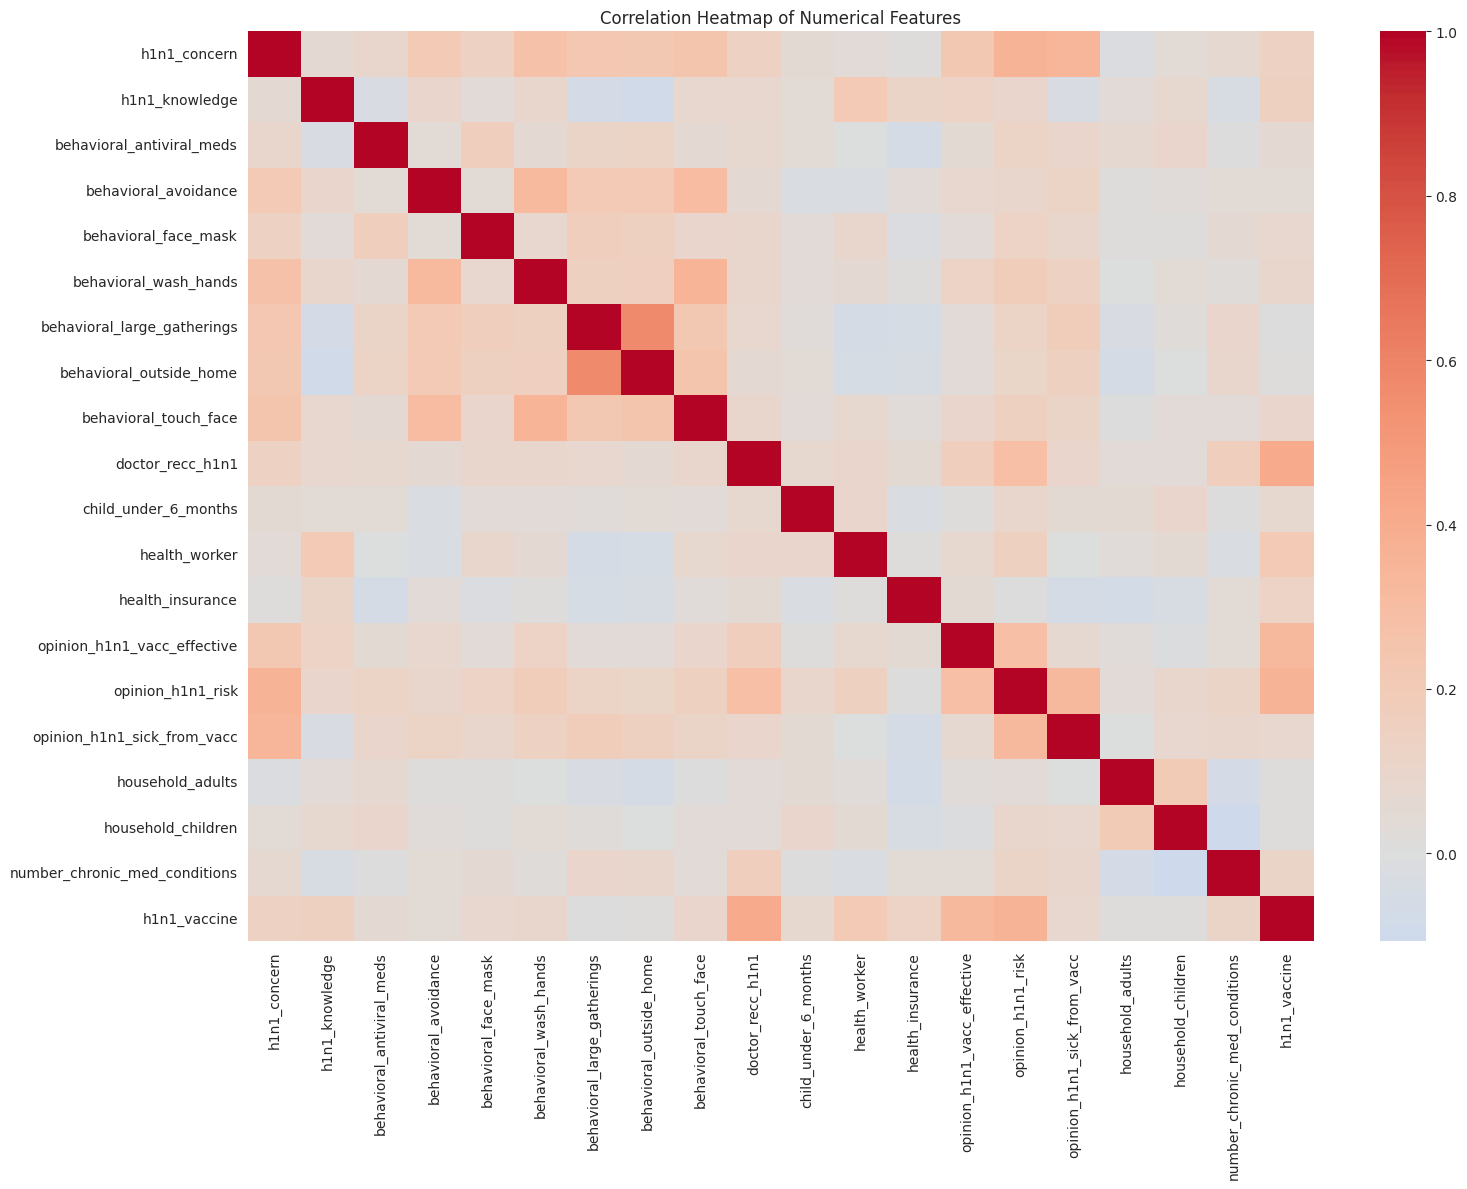

In [79]:

numeric_df = train_df.select_dtypes(
    include=["number"]
).drop(columns=["respondent_id"], errors="ignore")

plt.figure(figsize=(16, 12))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


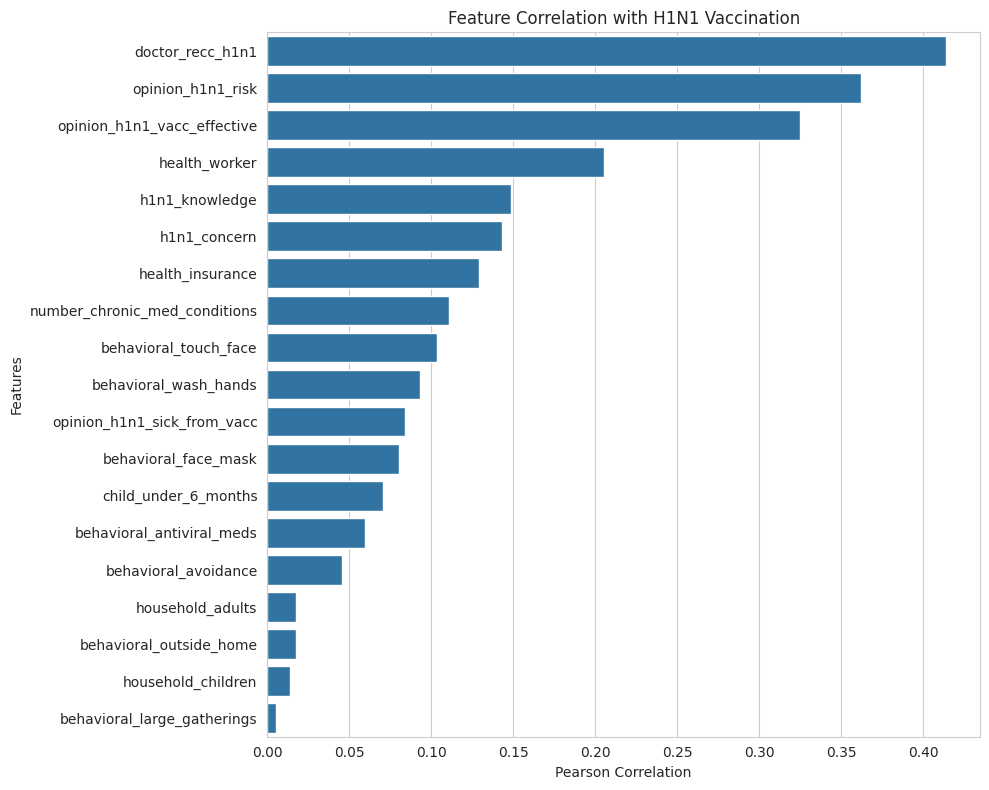

In [80]:

correlation = (
    numeric_df.corr()["h1n1_vaccine"]
    .drop("h1n1_vaccine")
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 8))

sns.barplot(
    x=correlation.values,
    y=correlation.index
)

plt.title("Feature Correlation with H1N1 Vaccination")
plt.xlabel("Pearson Correlation")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


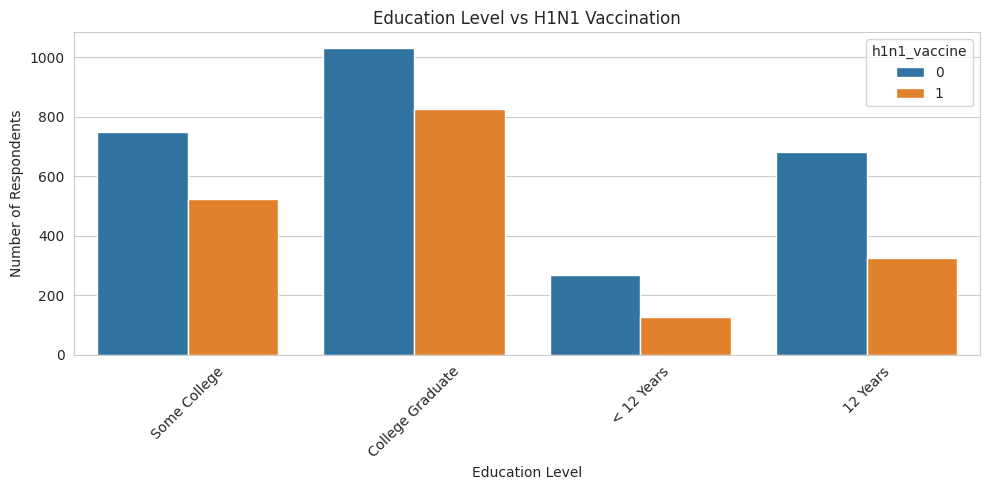

In [81]:


plt.figure(figsize=(10, 5))

sns.countplot(
    data=train_df,
    x="education",
    hue="h1n1_vaccine"
)

plt.title("Education Level vs H1N1 Vaccination")
plt.xlabel("Education Level")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


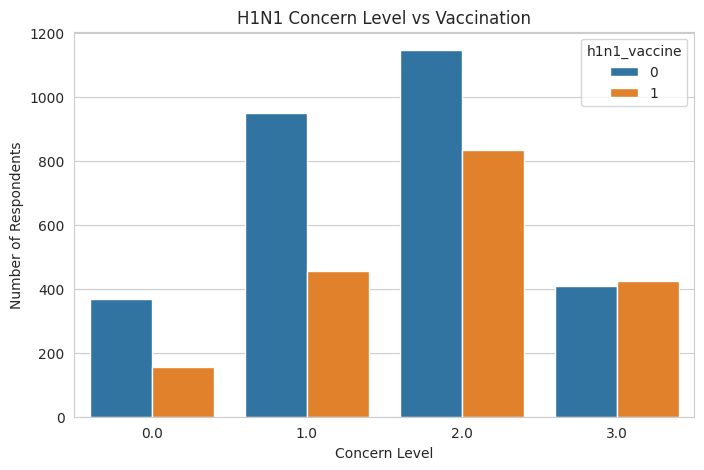

In [82]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="h1n1_concern",
    hue="h1n1_vaccine"
)

plt.title("H1N1 Concern Level vs Vaccination")
plt.xlabel("Concern Level")
plt.ylabel("Number of Respondents")
plt.show()


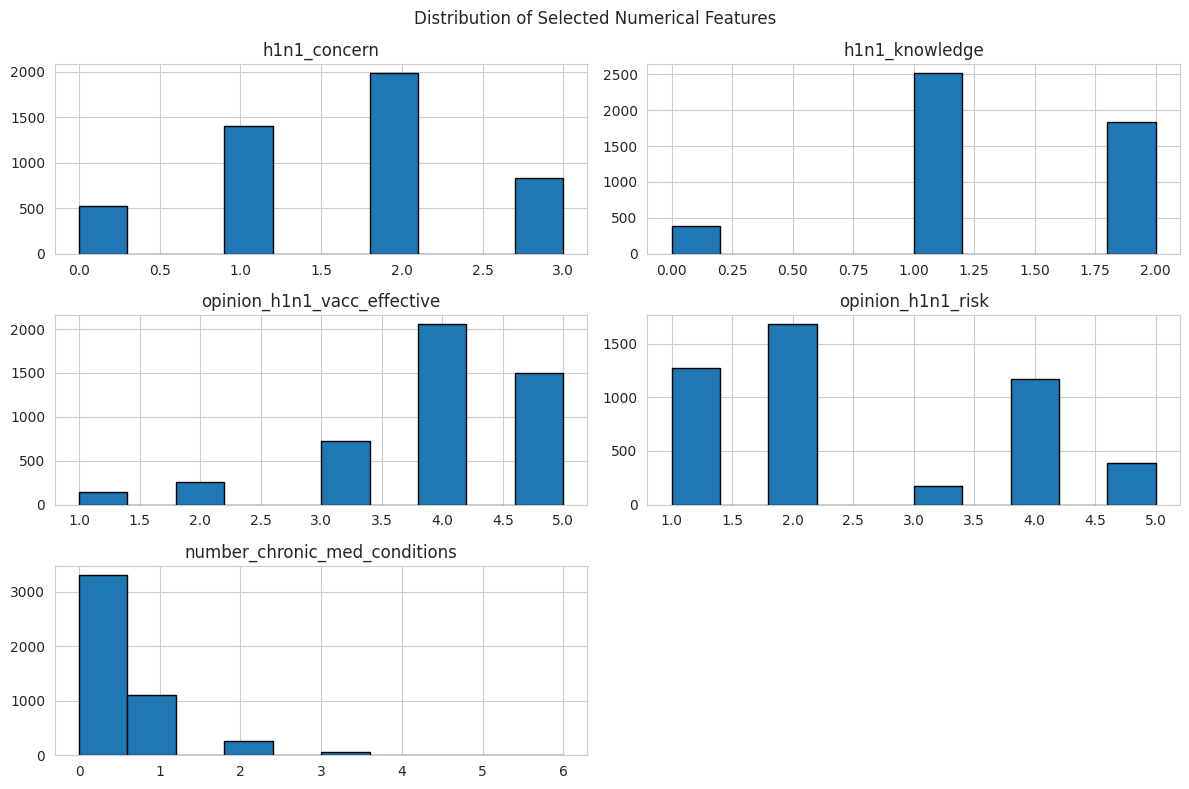

In [83]:

features = [
    "h1n1_concern",
    "h1n1_knowledge",
    "opinion_h1n1_vacc_effective",
    "opinion_h1n1_risk",
    "number_chronic_med_conditions"
]

train_df[features].hist(
    figsize=(12, 8),
    bins=10,
    edgecolor="black"
)

plt.suptitle("Distribution of Selected Numerical Features")
plt.tight_layout()
plt.show()


In [84]:

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTesting columns:")
print(test_df.columns.tolist())

print("\nColumns only in training:")
print(
    set(train_df.columns) - set(test_df.columns)
)

print("\nColumns only in testing:")
print(
    set(test_df.columns) - set(train_df.columns)
)


Training shape: (4756, 31)
Testing shape: (4749, 30)

Training columns:
['respondent_id', 'h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'household_adults', 'household_children', 'employment_sector', 'number_chronic_med_conditions', 'h1n1_vaccine']

Testing columns:
['respondent_id', 'h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_

In [85]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)


In [86]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 1. Separate features and target from train_df
X = train_df.drop(columns=['respondent_id', 'h1n1_vaccine'])
y = train_df['h1n1_vaccine']

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# 2. Build Preprocessing Pipelines
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# 3. Split into Train and Validation sets
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Transform features
X_train_processed = preprocessor.fit_transform(X_train)
X_valid_processed = preprocessor.transform(X_valid)

# 5. Initialize and Train Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_processed, y_train)

lr_pred = lr_model.predict(X_valid_processed)

print("Logistic Regression Accuracy:",
      accuracy_score(y_valid, lr_pred))

print("\nClassification Report:")
print(classification_report(y_valid, lr_pred))

Logistic Regression Accuracy: 0.7605042016806722

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.85      0.81       577
           1       0.73      0.62      0.67       375

    accuracy                           0.76       952
   macro avg       0.75      0.74      0.74       952
weighted avg       0.76      0.76      0.76       952



In [87]:

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train_processed, y_train)

dt_pred = dt_model.predict(X_valid_processed)

print("Decision Tree Accuracy:",
      accuracy_score(y_valid, dt_pred))

print("\nClassification Report:")
print(classification_report(y_valid, dt_pred))


Decision Tree Accuracy: 0.7542016806722689

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.84      0.81       577
           1       0.72      0.62      0.66       375

    accuracy                           0.75       952
   macro avg       0.75      0.73      0.74       952
weighted avg       0.75      0.75      0.75       952



In [88]:

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_valid_processed)

print("Random Forest Accuracy:",
      accuracy_score(y_valid, rf_pred))

print("\nClassification Report:")
print(classification_report(y_valid, rf_pred))


Random Forest Accuracy: 0.7510504201680672

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.85      0.81       577
           1       0.72      0.59      0.65       375

    accuracy                           0.75       952
   macro avg       0.74      0.72      0.73       952
weighted avg       0.75      0.75      0.75       952



In [89]:

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train_processed, y_train)

xgb_pred = xgb_model.predict(X_valid_processed)

print("XGBoost Accuracy:",
      accuracy_score(y_valid, xgb_pred))

print("\nClassification Report:")
print(classification_report(y_valid, xgb_pred))


XGBoost Accuracy: 0.7478991596638656

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.83      0.80       577
           1       0.70      0.62      0.66       375

    accuracy                           0.75       952
   macro avg       0.74      0.73      0.73       952
weighted avg       0.74      0.75      0.74       952



In [90]:
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():

    # Use the preprocessed validation data X_valid_processed instead of the raw X_valid
    y_pred = model.predict(X_valid_processed)
    y_prob = model.predict_proba(X_valid_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Precision": precision_score(
            y_valid, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_valid, y_pred, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_valid, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC AUC",
    ascending=False
)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.7605,0.7290,0.6240,0.6724,0.8166
3,XGBoost,0.7479,0.7039,0.6213,0.6601,0.8081
2,Random Forest,0.7511,0.7240,0.5947,0.6530,0.8034
1,Decision Tree,0.7542,0.7196,0.6160,0.6638,0.7903


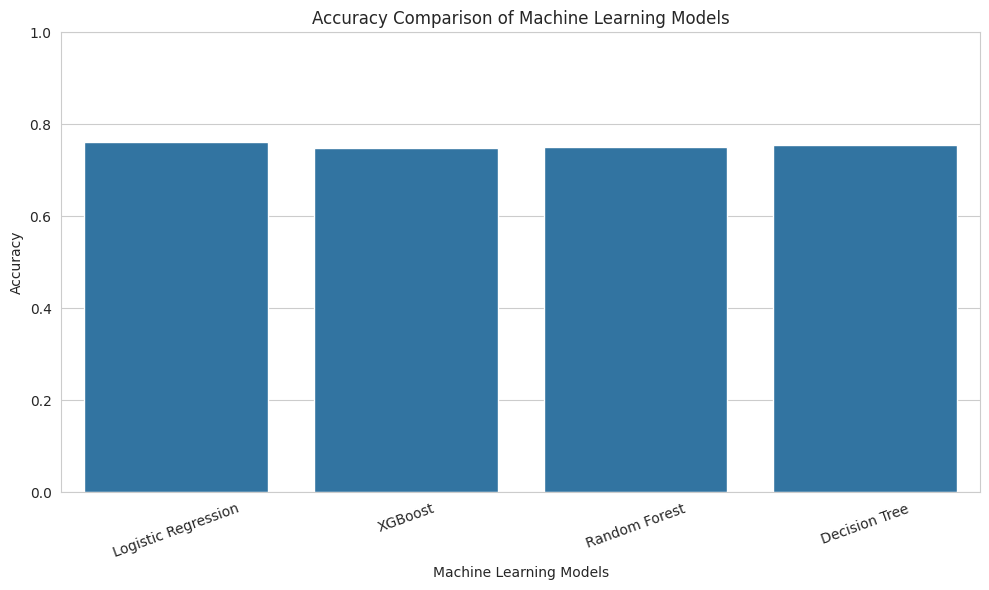

In [91]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


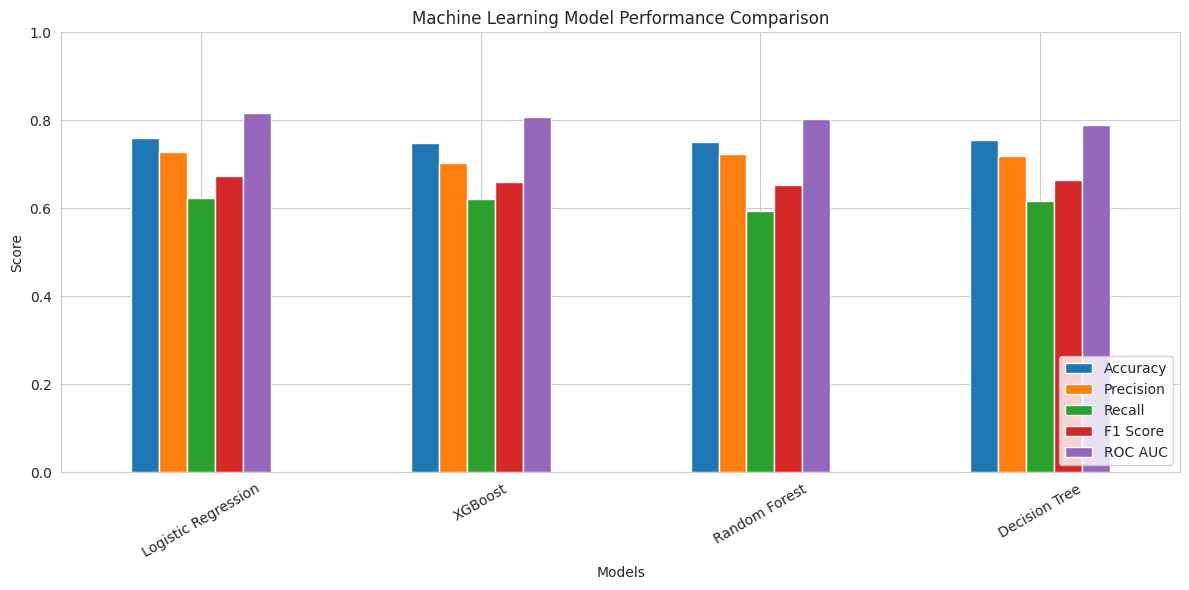

In [92]:

metrics_df = results_df.set_index("Model")

metrics_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [93]:

best_name = results_df.iloc[0]["Model"]

best_model = models[best_name]

print("Best Performing Model:", best_name)

print(
    "Best ROC-AUC:",
    results_df.iloc[0]["ROC AUC"]
)


Best Performing Model: Logistic Regression
Best ROC-AUC: 0.8165545927209705


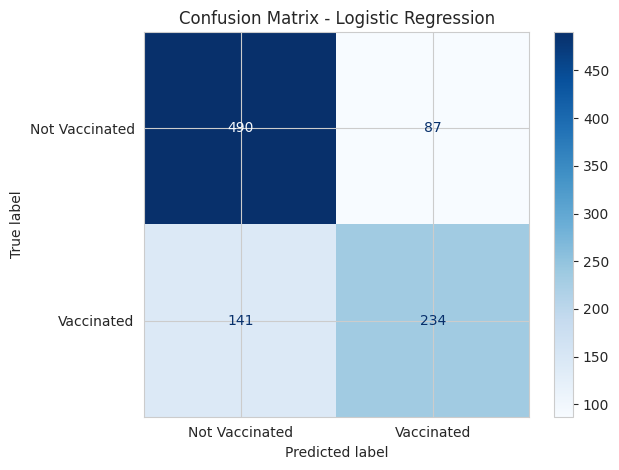

In [94]:
y_pred = best_model.predict(X_valid_processed)

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    y_pred,
    labels=[0, 1],
    display_labels=[
        "Not Vaccinated",
        "Vaccinated"
    ],
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()

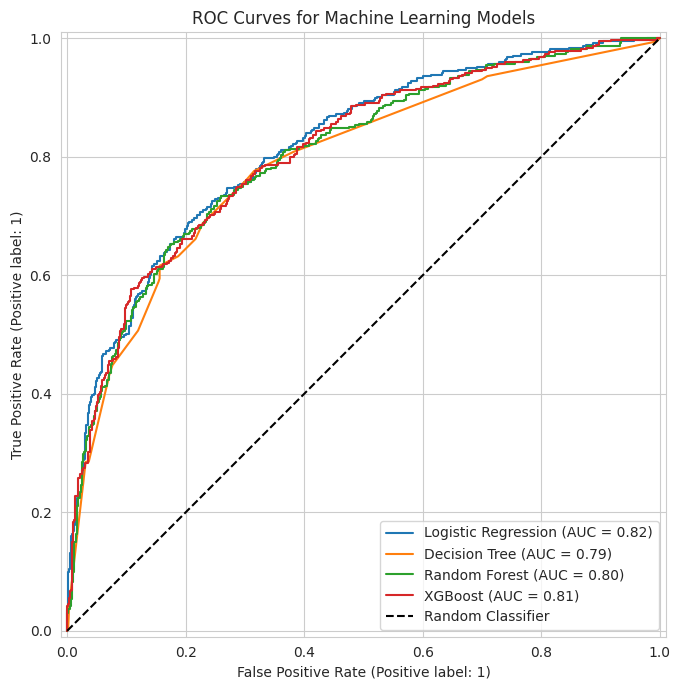

In [95]:

fig, ax = plt.subplots(figsize=(9, 7))

for name, model in models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_valid_processed,
        y_valid,
        name=name,
        ax=ax
    )

plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random Classifier"
)

plt.title("ROC Curves for Machine Learning Models")
plt.legend()
plt.tight_layout()
plt.show()


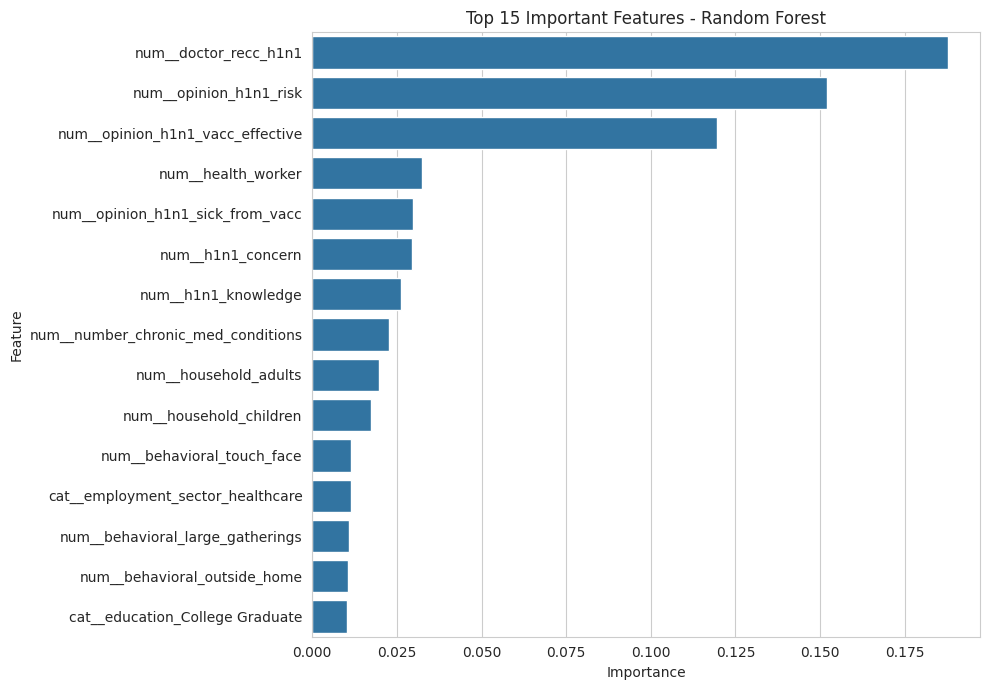

In [96]:

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Random Forest")
plt.tight_layout()
plt.show()


In [97]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=10,
    cv=5,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(random_search.best_score_)


Best Parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 4, 'classifier__max_depth': 15}

Best Cross-Validation ROC-AUC:
0.827287037775956


In [98]:
tuned_rf_model = random_search.best_estimator_

# Pass raw X_valid because tuned_rf_model is a Pipeline containing the preprocessor
tuned_pred = tuned_rf_model.predict(X_valid)

tuned_prob = tuned_rf_model.predict_proba(
    X_valid
)[:, 1]

print("Tuned Random Forest Performance")

print(
    "Accuracy:",
    accuracy_score(y_valid, tuned_pred)
)

print(
    "F1 Score:",
    f1_score(y_valid, tuned_pred)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_valid, tuned_prob)
)

print("\nClassification Report:")
print(classification_report(y_valid, tuned_pred))

Tuned Random Forest Performance
Accuracy: 0.759453781512605
F1 Score: 0.6656934306569343
ROC-AUC: 0.8025465049104563

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.86      0.81       577
           1       0.74      0.61      0.67       375

    accuracy                           0.76       952
   macro avg       0.75      0.73      0.74       952
weighted avg       0.76      0.76      0.75       952



In [99]:

import joblib

best_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", best_model)
])

# Fit on original training subset
best_pipeline.fit(X_train, y_train)

joblib.dump(
    best_pipeline,
    "best_h1n1_model.pkl"
)

print("Best model saved successfully!")


Best model saved successfully!


In [100]:

best_name = results_df.sort_values(
    by="ROC AUC",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_name]

print("Selected Best Model:", best_name)


Selected Best Model: Logistic Regression


In [101]:

from sklearn.pipeline import Pipeline
from sklearn.base import clone

final_pipeline = Pipeline(steps=[
    ("preprocessing", clone(preprocessor)),
    ("classifier", clone(best_model))
])

final_pipeline.fit(X, y)

print("Final model trained successfully!")


Final model trained successfully!


In [104]:
# Drop the metadata column respondent_id to match the training feature set
X_submission = test_df.drop(columns=['respondent_id'])

test_predictions = final_pipeline.predict(
    X_submission
)

print("Total predictions:", len(test_predictions))

print("First 10 predictions:")
print(test_predictions[:10])

Total predictions: 4749
First 10 predictions:
[0 0 0 0 0 1 1 1 1 0]


In [105]:

submission = pd.DataFrame({
    "respondent_id": test_df["respondent_id"],
    "h1n1_vaccine": test_predictions.astype(int)
})

display(submission.head(10))

print("Submission shape:", submission.shape)


,respondent_id,h1n1_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0
5,4762,1
6,4763,1
7,4764,1
8,4765,1
9,4766,0


Submission shape: (4749, 2)


In [106]:

print("Missing values:")
print(submission.isnull().sum())

print("\nDuplicate respondent IDs:")
print(submission["respondent_id"].duplicated().sum())

print("\nPrediction distribution:")
print(submission["h1n1_vaccine"].value_counts())

print("\nSubmission columns:")
print(submission.columns.tolist())

assert len(submission) == len(test_df)

assert submission["h1n1_vaccine"].isin([0, 1]).all()

assert submission["respondent_id"].equals(
    test_df["respondent_id"]
)

print("\nSubmission validation successful!")


Missing values:
respondent_id    0
h1n1_vaccine     0
dtype: int64

Duplicate respondent IDs:
0

Prediction distribution:
h1n1_vaccine
0    3122
1    1627
Name: count, dtype: int64

Submission columns:
['respondent_id', 'h1n1_vaccine']

Submission validation successful!


In [107]:

submission.to_csv(
    "dataset_B_final_submission.csv",
    index=False
)

print("Submission file created successfully!")


Submission file created successfully!


In [108]:
# Install XGBoost if needed
%pip install -q xgboost

import pandas as pd
import os
import zipfile

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from xgboost import XGBClassifier

# 1. LOAD DATASETS (Updated with correct paths)
train_df = pd.read_csv("/content/sample_data/dataset_B_training.csv")
test_df = pd.read_csv("/content/sample_data/dataset_B_testing.csv")

train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()

# 2. SEPARATE FEATURES AND TARGET
X = train_df.drop(columns=["respondent_id", "h1n1_vaccine"])
y = train_df["h1n1_vaccine"]

X_test = test_df.drop(columns=["respondent_id"])
X_test = X_test[X.columns]

# 3. IDENTIFY FEATURES
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

# 4. PREPROCESSING
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

# 5. DEFINE FIVE MODELS
models = {
    "Logistic_Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Decision_Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "Random_Forest": RandomForestClassifier(
        n_estimators=200, max_depth=10, random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42
    ),
    "Gradient_Boosting": GradientBoostingClassifier(
        n_estimators=200, random_state=42
    )
}

# 6. CREATE OUTPUT FOLDER
os.makedirs("/content/submission_files", exist_ok=True)

# 7. TRAIN AND GENERATE FIVE CSV FILES
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X, y)

    predictions = pipeline.predict(X_test)

    submission = pd.DataFrame({
        "respondent_id": test_df["respondent_id"],
        "h1n1_vaccine": predictions.astype(int)
    })

    filename = f"/content/submission_files/{name}_submission.csv"

    submission.to_csv(filename, index=False)

    print(f"Created: {name}_submission.csv")
    print("Shape:", submission.shape)

# 8. ZIP ALL FIVE CSV FILES
zip_path = "/content/All_5_Submission_Files.zip"

with zipfile.ZipFile(zip_path, "w") as zipf:
    for filename in os.listdir("/content/submission_files"):
        if filename.endswith(".csv"):
            zipf.write(
                f"/content/submission_files/{filename}",
                arcname=filename
            )

print("\nAll 5 CSV files generated successfully!")

# 9. DOWNLOAD ZIP
from google.colab import files
files.download(zip_path)

Created: Logistic_Regression_submission.csv
Shape: (4749, 2)
Created: Decision_Tree_submission.csv
Shape: (4749, 2)
Created: Random_Forest_submission.csv
Shape: (4749, 2)
Created: XGBoost_submission.csv
Shape: (4749, 2)
Created: Gradient_Boosting_submission.csv
Shape: (4749, 2)

All 5 CSV files generated successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>